In [9]:
import os, shutil, glob

os.chdir(r"C:\Users\Alive\Documents\eeg-brain-networks-dementia")
os.makedirs("data/ds004504/derivatives", exist_ok=True)

for sub in ["sub-001", "sub-037", "sub-066"]:
    src = f"notebooks/data/ds004504/derivatives/{sub}"
    dst = f"data/ds004504/derivatives/{sub}"
    if os.path.exists(src) and not os.path.exists(dst):
        shutil.move(src, dst)

print(glob.glob("data/ds004504/derivatives/*/eeg/*.set"))

['data/ds004504/derivatives\\sub-001\\eeg\\sub-001_task-eyesclosed_eeg.set', 'data/ds004504/derivatives\\sub-037\\eeg\\sub-037_task-eyesclosed_eeg.set', 'data/ds004504/derivatives\\sub-066\\eeg\\sub-066_task-eyesclosed_eeg.set']


In [12]:
import os
os.chdir(r"C:\Users\Alive\Documents\eeg-brain-networks-dementia")
print(os.getcwd())

c:\Users\Alive\Documents\eeg-brain-networks-dementia


In [11]:
import mne
path = glob.glob("data/ds004504/derivatives/sub-001/eeg/*.set")[0]
raw = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
print(raw)

<RawEEGLAB | sub-001_task-eyesclosed_eeg.set, 19 x 299900 (599.8 s), ~43.5 MiB, data loaded>


In [10]:
if os.path.exists("notebooks/data"):
    shutil.rmtree("notebooks/data")
print(sorted(os.listdir("notebooks")))

['.gitkeep', '01_audit.ipynb', '02_epochs.ipynb']


In [1]:
import os
os.chdir("..")
print(os.getcwd())

c:\Users\Alive\Documents\eeg-brain-networks-dementia


In [13]:
import os, shutil, glob

os.makedirs("data/ds004504/derivatives", exist_ok=True)

for sub in ["sub-001", "sub-037", "sub-066"]:
    src = f"notebooks/data/ds004504/derivatives/{sub}"
    dst = f"data/ds004504/derivatives/{sub}"
    if os.path.exists(src) and not os.path.exists(dst):
        shutil.move(src, dst)

print(glob.glob("data/ds004504/derivatives/*/eeg/*.set"))

['data/ds004504/derivatives\\sub-001\\eeg\\sub-001_task-eyesclosed_eeg.set', 'data/ds004504/derivatives\\sub-037\\eeg\\sub-037_task-eyesclosed_eeg.set', 'data/ds004504/derivatives\\sub-066\\eeg\\sub-066_task-eyesclosed_eeg.set']


Matplotlib is building the font cache; this may take a moment.


Using matplotlib as 2D backend.
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


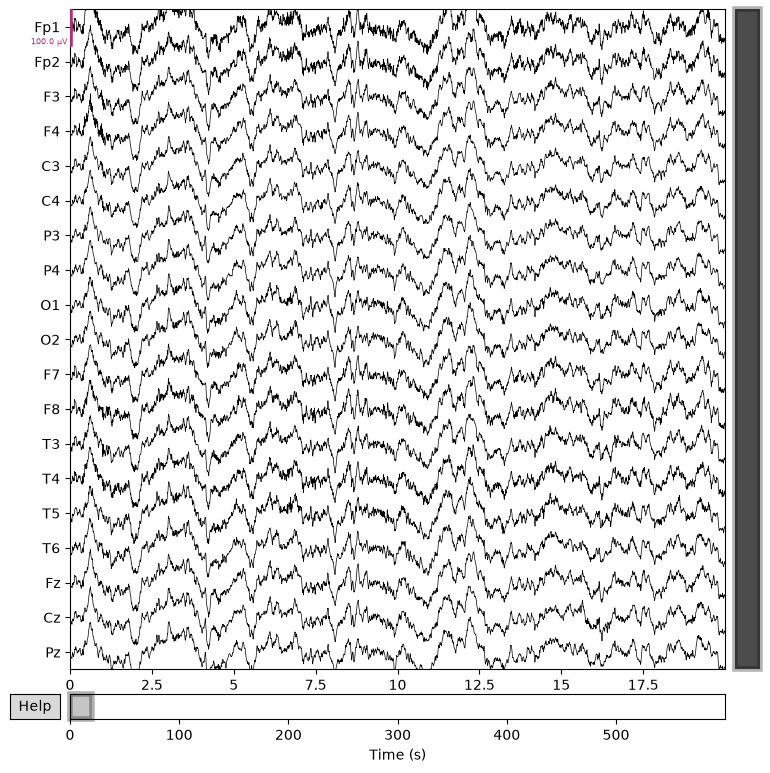

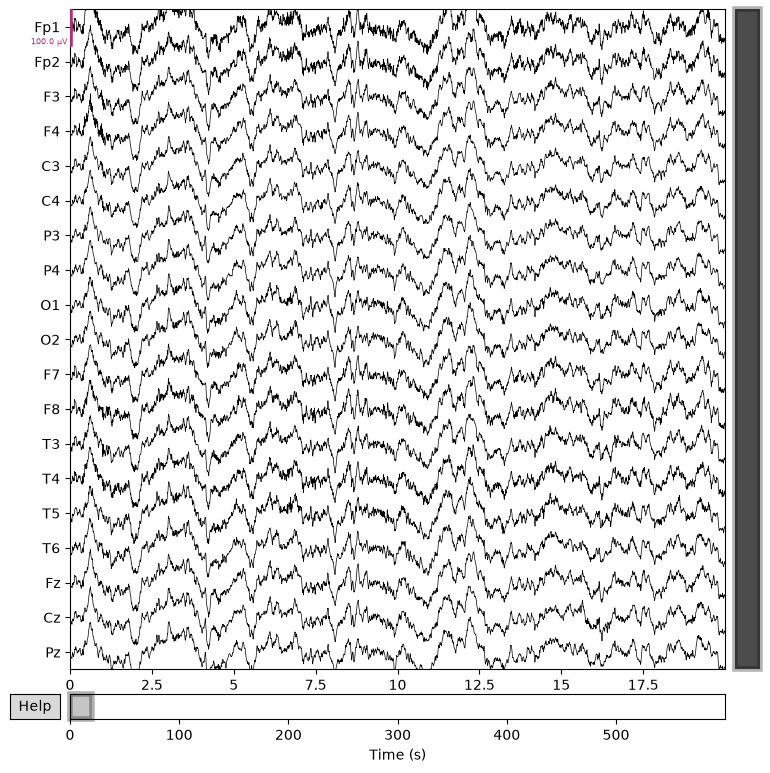

In [14]:
%matplotlib inline
raw.plot(duration=20, n_channels=19, scalings=dict(eeg=50e-6))

Effective window size : 4.096 (s)
Plotting power spectral density (dB=True).


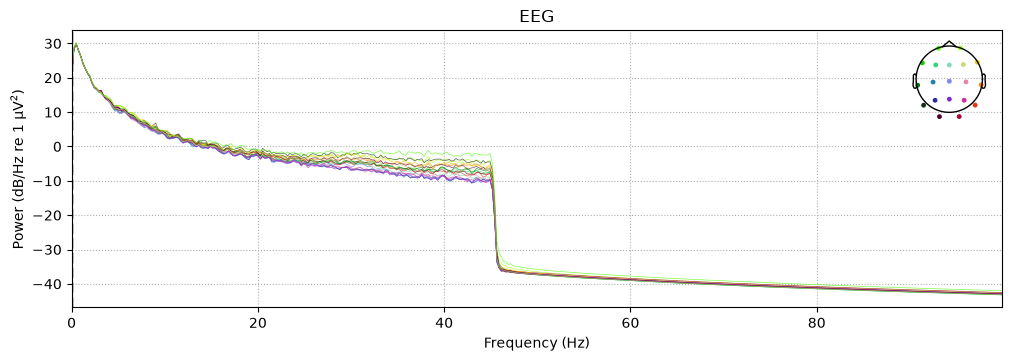

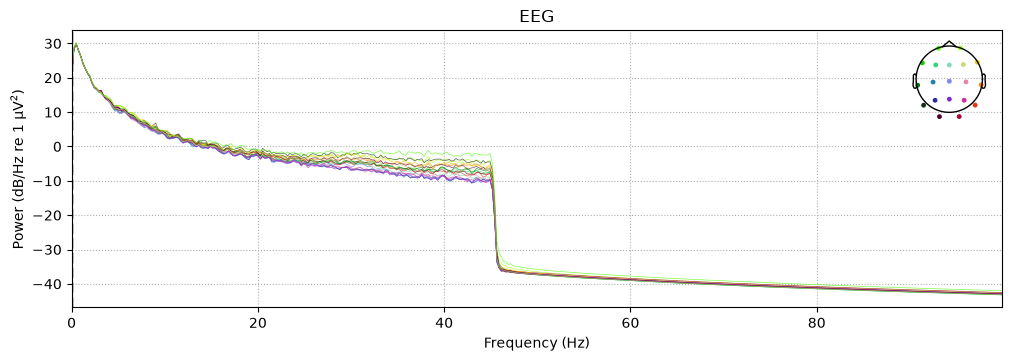

In [15]:
raw.compute_psd(fmin=0, fmax=100).plot()

In [16]:
import numpy as np
data = raw.get_data()
print("Std of signal:", data.std())
print("Max absolute value:", np.abs(data).max())

Std of signal: 3.1830183333429606e-05
Max absolute value: 0.00016151979064941405


In [17]:
epochs = mne.make_fixed_length_epochs(raw, duration=4.0, preload=True, verbose=False)
print("Epochs before rejection:", len(epochs))
print(epochs)

Epochs before rejection: 149
<Epochs | 149 events (all good), 0 – 3.998 s (baseline off), ~43.2 MiB, data loaded,
 '1': 149>


Epochs kept: 42


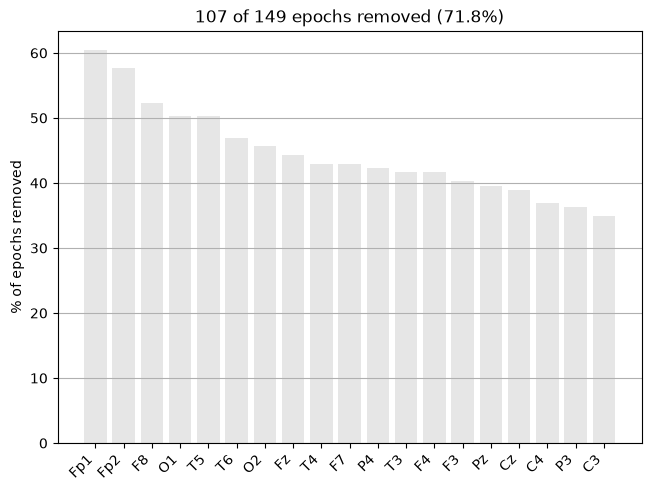

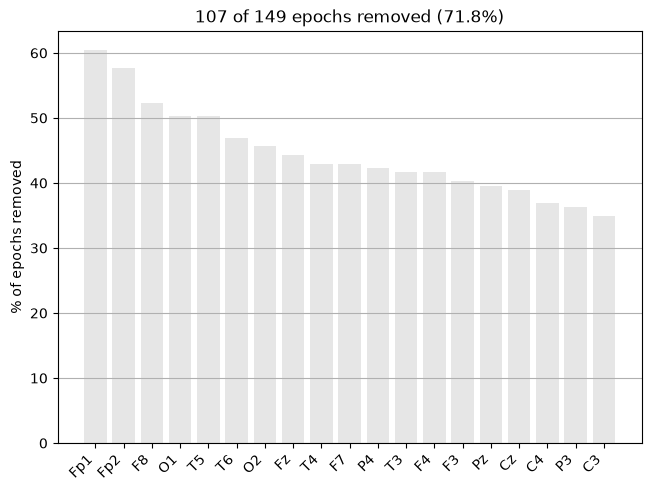

In [18]:
epochs.drop_bad(reject=dict(eeg=150e-6), verbose=False)
print("Epochs kept:", len(epochs))
epochs.plot_drop_log()

In [19]:
os.makedirs("data/epochs", exist_ok=True)
ep60 = epochs[:60]
print(len(ep60), ep60.info["nchan"], ep60.info["sfreq"])
ep60.save("data/epochs/sub-001-epo.fif", overwrite=True)

42 19 500.0


[WindowsPath('c:/Users/Alive/Documents/eeg-brain-networks-dementia/data/epochs/sub-001-epo.fif')]

In [20]:
import numpy as np
epochs_all = mne.make_fixed_length_epochs(raw, duration=4.0, preload=True, verbose=False)
ptp = np.ptp(epochs_all.get_data(), axis=2)      # epochs x channels
worst = ptp.max(axis=1) * 1e6                    # worst channel per epoch, in µV
print("Percentiles (10, 25, 50, 75, 90, 100):", np.percentile(worst, [10, 25, 50, 75, 90, 100]).round(0))
for t in [150, 200, 250, 300, 400]:
    print(f"threshold {t} µV -> kept {(worst < t).sum()} of {len(worst)}")

Percentiles (10, 25, 50, 75, 90, 100): [135. 149. 163. 181. 202. 264.]
threshold 150 µV -> kept 42 of 149
threshold 200 µV -> kept 131 of 149
threshold 250 µV -> kept 146 of 149
threshold 300 µV -> kept 149 of 149
threshold 400 µV -> kept 149 of 149


In [21]:
import numpy as np

def worst_ptp(sub_id):
    p = glob.glob(f"data/ds004504/derivatives/{sub_id}/eeg/*.set")[0]
    r = mne.io.read_raw_eeglab(p, preload=True, verbose=False)
    e = mne.make_fixed_length_epochs(r, duration=4.0, preload=True, verbose=False)
    return np.ptp(e.get_data(), axis=2).max(axis=1) * 1e6

for sub, grp in [("sub-001", "AD"), ("sub-037", "CN"), ("sub-066", "FTD")]:
    w = worst_ptp(sub)
    pct = np.percentile(w, [10, 50, 90, 100]).round(0)
    kept = {t: int((w < t).sum()) for t in [150, 200, 250, 300]}
    print(sub, grp, "| n =", len(w), "| percentiles 10/50/90/100:", pct, "| kept:", kept)

sub-001 AD | n = 149 | percentiles 10/50/90/100: [135. 163. 202. 264.] | kept: {150: 42, 200: 131, 250: 146, 300: 149}
sub-037 CN | n = 194 | percentiles 10/50/90/100: [154. 194. 238. 463.] | kept: {150: 14, 200: 113, 250: 182, 300: 190}
sub-066 FTD | n = 137 | percentiles 10/50/90/100: [150. 182. 225. 315.] | kept: {150: 13, 200: 101, 250: 132, 300: 136}


C:\Users\Alive\AppData\Local\Temp\ipykernel_11680\2888277657.py:5: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  r = mne.io.read_raw_eeglab(p, preload=True, verbose=False)


In [22]:
import pandas as pd

def load_clean_epochs(sub_id, n_keep=60, reject_uv=250):
    """Load one subject, cut 4-s epochs, drop those above reject_uv, keep the first n_keep."""
    path = glob.glob(f"data/ds004504/derivatives/{sub_id}/eeg/*.set")[0]
    raw = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
    n_boundary = sum("boundary" in d.lower() for d in raw.annotations.description)
    epochs = mne.make_fixed_length_epochs(raw, duration=4.0, preload=True, verbose=False)
    n_total = len(epochs)
    epochs.drop_bad(reject=dict(eeg=reject_uv * 1e-6), verbose=False)
    n_clean = len(epochs)
    epochs = epochs[:n_keep]
    log = dict(participant_id=sub_id, n_boundary_marks=n_boundary, n_total=n_total,
               n_clean=n_clean, n_kept=len(epochs), reject_uv=reject_uv)
    return epochs, log

os.makedirs("data/epochs", exist_ok=True)
logs = []
for sub in ["sub-001", "sub-037", "sub-066"]:
    ep, log = load_clean_epochs(sub)
    ep.save(f"data/epochs/{sub}-epo.fif", overwrite=True, verbose=False)
    logs.append(log)

counts = pd.DataFrame(logs).merge(df[["participant_id", "Group"]], on="participant_id")
print(counts)
counts.to_csv("results/tables/epoch_counts.csv", index=False)

C:\Users\Alive\AppData\Local\Temp\ipykernel_11680\833923443.py:6: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(path, preload=True, verbose=False)


NameError: name 'df' is not defined

In [23]:
import pandas as pd

df = pd.read_csv("data/ds004504/participants.tsv", sep="\t")
counts = pd.DataFrame(logs).merge(df[["participant_id", "Group"]], on="participant_id")
print(counts)
counts.to_csv("results/tables/epoch_counts.csv", index=False)

  participant_id  n_boundary_marks  n_total  n_clean  n_kept  reject_uv Group
0        sub-001                 0      149      146      60        250     A
1        sub-037                 0      194      182      60        250     C
2        sub-066                 1      137      132      60        250     F


In [27]:
def load_clean_epochs(sub_id, n_keep=60, reject_uv=250):
    """Load one subject, cut 4-s epochs, drop those above reject_uv or crossing a boundary."""
    path = glob.glob(f"data/ds004504/derivatives/{sub_id}/eeg/*.set")[0]
    raw = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
    n_boundary = sum("boundary" in d.lower() for d in raw.annotations.description)
    raw.annotations.description[:] = [
        "BAD_boundary" if "boundary" in d.lower() else d for d in raw.annotations.description]
    epochs = mne.make_fixed_length_epochs(raw, duration=4.0, preload=True, verbose=False)
    n_total = len(epochs)
    epochs.drop_bad(reject=dict(eeg=reject_uv * 1e-6), verbose=False)
    n_clean = len(epochs)
    n_dropped_boundary = sum("BAD_boundary" in x for x in epochs.drop_log)
    epochs = epochs[:n_keep]
    log = dict(participant_id=sub_id, n_boundary_marks=n_boundary, n_total=n_total,
               n_clean=n_clean, n_dropped_boundary=n_dropped_boundary,
               n_kept=len(epochs), reject_uv=reject_uv)
    return epochs, log

In [29]:
ep, log = load_clean_epochs("sub-066")
print(log)

C:\Users\Alive\AppData\Local\Temp\ipykernel_11680\1881634115.py:4: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(path, preload=True, verbose=False)


{'participant_id': 'sub-066', 'n_boundary_marks': 1, 'n_total': 136, 'n_clean': 131, 'n_dropped_boundary': 1, 'n_kept': 60, 'reject_uv': 250}


In [30]:
import pandas as pd

df = pd.read_csv("data/ds004504/participants.tsv", sep="\t")
logs = []
for sub in ["sub-001", "sub-037", "sub-066"]:
    ep, log = load_clean_epochs(sub)
    ep.save(f"data/epochs/{sub}-epo.fif", overwrite=True, verbose=False)
    logs.append(log)

counts = pd.DataFrame(logs).merge(df[["participant_id", "Group"]], on="participant_id")
print(counts)
counts.to_csv("results/tables/epoch_counts.csv", index=False)

C:\Users\Alive\AppData\Local\Temp\ipykernel_11680\1881634115.py:4: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(path, preload=True, verbose=False)


  participant_id  n_boundary_marks  n_total  n_clean  n_dropped_boundary  \
0        sub-001                 0      149      146                   0   
1        sub-037                 0      194      182                   0   
2        sub-066                 1      136      131                   1   

   n_kept  reject_uv Group  
0      60        250     A  
1      60        250     C  
2      60        250     F  


In [31]:
import glob
import mne


def load_clean_epochs(sub_id, n_keep=60, reject_uv=250):
    """Load one subject, cut 4-s epochs, drop those above reject_uv or crossing a boundary."""
    path = glob.glob(f"data/ds004504/derivatives/{sub_id}/eeg/*.set")[0]
    raw = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
    n_boundary = sum("boundary" in d.lower() for d in raw.annotations.description)
    raw.annotations.description[:] = [
        "BAD_boundary" if "boundary" in d.lower() else d for d in raw.annotations.description]
    epochs = mne.make_fixed_length_epochs(raw, duration=4.0, preload=True, verbose=False)
    n_total = len(epochs)
    epochs.drop_bad(reject=dict(eeg=reject_uv * 1e-6), verbose=False)
    n_clean = len(epochs)
    n_dropped_boundary = sum("BAD_boundary" in x for x in epochs.drop_log)
    epochs = epochs[:n_keep]
    log = dict(participant_id=sub_id, n_boundary_marks=n_boundary, n_total=n_total,
               n_clean=n_clean, n_dropped_boundary=n_dropped_boundary,
               n_kept=len(epochs), reject_uv=reject_uv)
    return epochs, log

In [2]:
import os
os.chdir(r"C:\Users\Alive\Documents\eeg-brain-networks-dementia")
print(os.getcwd())
print(os.listdir("src"))

C:\Users\Alive\Documents\eeg-brain-networks-dementia
['.gitkeep', 'src']


In [3]:
print(os.listdir("src/src"))

['connectivity.py']


In [4]:
import shutil
for f in os.listdir("src/src"):
    shutil.move(os.path.join("src", "src", f), os.path.join("src", f))
os.rmdir("src/src")
print(os.listdir("src"))

['.gitkeep', 'connectivity.py']


In [5]:
%%writefile src/epoching.py
import glob
import mne


def load_clean_epochs(sub_id, n_keep=60, reject_uv=300):
    """Load one subject, cut 4-s epochs, drop those above reject_uv or crossing a boundary."""
    path = glob.glob(f"data/ds004504/derivatives/{sub_id}/eeg/*.set")[0]
    raw = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
    n_boundary = sum("boundary" in d.lower() for d in raw.annotations.description)
    raw.annotations.description[:] = [
        "BAD_boundary" if "boundary" in d.lower() else d for d in raw.annotations.description]
    epochs = mne.make_fixed_length_epochs(raw, duration=4.0, preload=True, verbose=False)
    n_total = len(epochs)
    epochs.drop_bad(reject=dict(eeg=reject_uv * 1e-6), verbose=False)
    n_clean = len(epochs)
    n_dropped_boundary = sum("BAD_boundary" in x for x in epochs.drop_log)
    epochs = epochs[:n_keep]
    log = dict(participant_id=sub_id, n_boundary_marks=n_boundary, n_total=n_total,
               n_clean=n_clean, n_dropped_boundary=n_dropped_boundary,
               n_kept=len(epochs), reject_uv=reject_uv)
    return epochs, log

Writing src/epoching.py


In [6]:
print(os.listdir("src"))

['.gitkeep', 'connectivity.py', 'epoching.py']


In [3]:
import os
os.chdir(r"C:\Users\Alive\Documents\eeg-brain-networks-dementia")
print(os.getcwd())

C:\Users\Alive\Documents\eeg-brain-networks-dementia


In [6]:
import sys, glob
import pandas as pd, mne
sys.path.append("src")
import epoching
mne.set_log_level("ERROR")

df = pd.read_csv("data/ds004504/participants.tsv", sep="\t")
os.makedirs("data/epochs", exist_ok=True)
logs = []
for k, sub in enumerate(df["participant_id"], 1):
    ep, log = epoching.load_clean_epochs(sub, n_keep=60, reject_uv=300)
    log["included"] = log["n_kept"] >= 60
    if log["included"]:
        ep.save(f"data/epochs/{sub}-epo.fif", overwrite=True, verbose=False)
    logs.append(log)
    print(f"[{k}/88] {sub}: clean {log['n_clean']}, kept {log['n_kept']}, "
          f"boundary-dropped {log['n_dropped_boundary']}, included {log['included']}")

counts = pd.DataFrame(logs).merge(df[["participant_id", "Group"]], on="participant_id")
counts.to_csv("results/tables/epoch_counts.csv", index=False)
print(counts.groupby("Group").agg(n=("participant_id", "count"),
                                  included=("included", "sum"),
                                  median_clean=("n_clean", "median"),
                                  min_clean=("n_clean", "min")))
print(len(glob.glob("data/epochs/*-epo.fif")))

[1/88] sub-001: clean 149, kept 60, boundary-dropped 0, included True
[2/88] sub-002: clean 196, kept 60, boundary-dropped 0, included True


C:\Users\Alive\Documents\eeg-brain-networks-dementia\src\epoching.py:8: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(path, preload=True, verbose=False)


[3/88] sub-003: clean 75, kept 60, boundary-dropped 1, included True


C:\Users\Alive\Documents\eeg-brain-networks-dementia\src\epoching.py:8: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(path, preload=True, verbose=False)


[4/88] sub-004: clean 172, kept 60, boundary-dropped 2, included True
[5/88] sub-005: clean 192, kept 60, boundary-dropped 0, included True


...

[86/88] sub-086: clean 7, kept 7, boundary-dropped 56, included False


C:\Users\Alive\Documents\eeg-brain-networks-dementia\src\epoching.py:8: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(path, preload=True, verbose=False)


[87/88] sub-087: clean 147, kept 60, boundary-dropped 3, included True


C:\Users\Alive\Documents\eeg-brain-networks-dementia\src\epoching.py:8: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(path, preload=True, verbose=False)


[88/88] sub-088: clean 187, kept 60, boundary-dropped 8, included True
        n  included  median_clean  min_clean
Group                                       
A      36        36         190.0         75
C      29        29         193.0        128
F      23        22         165.0          7
87
